# Q5 and Q6. Functional connectivity between areas

- **Q5:** which pair of areas has the strongest **undirected** functional connectivity (1⇔2, 1⇔3, 2⇔3)?
- **Q6:** which pair has the strongest **directed** connectivity, among the three directions offered: **1⇒2, 3⇒2, 3⇒1**?

**Why the usual measures can't be used as they are.** All channels share one external reference, and Q3 showed large transients (movement/EMG) that hit all areas **at the same instant**.
Both make any two areas look coupled with **zero time lag**, even when nothing passes between them. Two choices handle this:

1. **Local re-referencing.** Each signal is the difference of two neighbouring channels of the same area (a *bipolar derivation*). This removes the shared reference and distant sources. Six such signals are taken per area, spread over depth.
2. **Lag-based measures.** Real communication between areas takes time, so the main measures only count coupling with a **non-zero** lag:
   - **Q5: weighted phase lag index (wPLI).** It measures how consistently one signal's phase leads or lags the other's. It is 0 for pure zero-lag mixing and up to 1 for a perfectly consistent lag.
   - **Q6: phase slope index (PSI).** If x drives y with a delay τ, their phase difference grows with frequency (Δφ = 2πfτ). The sign of that slope says **who leads**. Like wPLI, it ignores zero-lag mixing.

**Checks:**
- coherence (which zero-lag mixing *does* inflate);
- cross-area spike STTC, as in Q4 but with units from two areas;
- **Granger causality** on the LFP: does the past of x improve the prediction of y?
- Granger causality on population spike rates.

All measures cover the whole recording and 1–100 Hz. Every mouse contributes one value per pair (the mean over its 36 channel pairs); the statistics are across the 18 mice.
The code lives in `c2p/q05_06_connectivity.py`. Its conventions were checked on simulated data: PSI > 0 and Granger x→y > y→x when x drives y, and wPLI ≈ 0 for pure zero-lag mixing.

In [1]:
import sys; sys.path.insert(0, "..")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats as sps

from c2p import RESULTS_DIR
from c2p import q05_06_connectivity as q

lfp, spec, spk = q.compute()                 # cached; q.compute(force=True) recomputes (~10 min)
xsttc = q.compute_cross_sttc()
f = spec["freqs"]
PAIRS = [(1, 2), (1, 3), (2, 3)]
PAIR_COLORS = {(1, 2): "tab:purple", (1, 3): "tab:cyan", (2, 3): "tab:olive"}
name = lambda p: f"{p[0]}⇔{p[1]}"
mice_ids = sorted(lfp.mouse.unique())
print(f"{len(lfp):,} LFP channel pairs, {len(xsttc):,} cross-area unit pairs, {len(mice_ids)} mice")

1,944 LFP channel pairs, 39,325 cross-area unit pairs, 18 mice


# Q5: undirected connectivity

## 1. wPLI and coherence across frequencies

These are the mean over mice (±SEM). Coherence is high at low frequencies for every pair, as expected if much of it is shared zero-lag signal. wPLI shows only the lagged part.

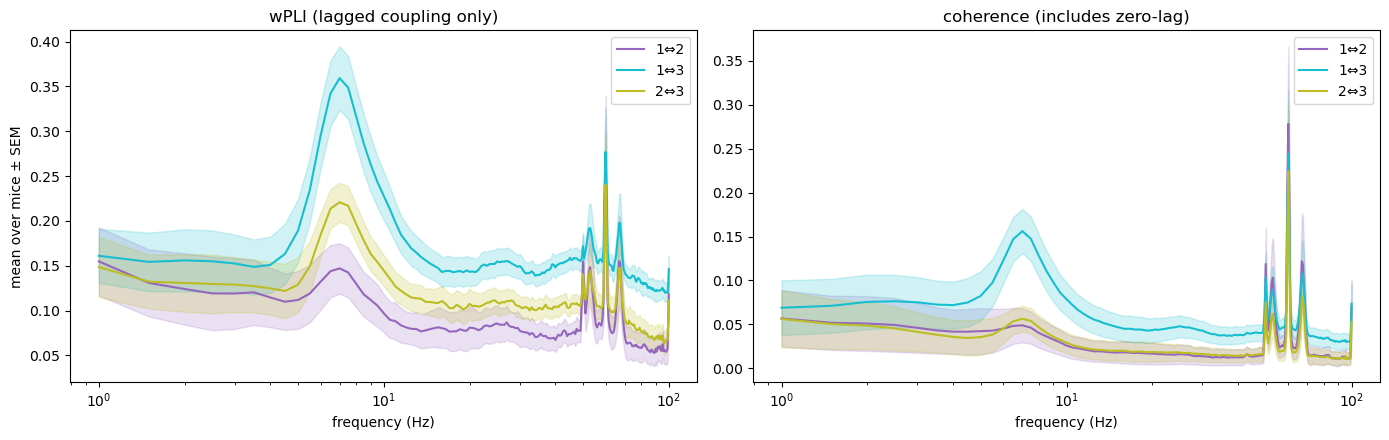

In [2]:
fig, axs = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, kind in zip(axs, ["wpli", "coh"]):
    for p in PAIRS:
        s = np.array([spec[f"m{m}_{p[0]}{p[1]}_{kind}"] for m in mice_ids])
        mu, se = s.mean(0), s.std(0, ddof=1) / np.sqrt(len(s))
        sel = (f >= 1) & (f <= 100)
        ax.plot(f[sel], mu[sel], color=PAIR_COLORS[p], label=name(p))
        ax.fill_between(f[sel], (mu - se)[sel], (mu + se)[sel], color=PAIR_COLORS[p], alpha=0.2)
    ax.set(xscale="log", xlabel="frequency (Hz)", title={"wpli": "wPLI (lagged coupling only)", "coh": "coherence (includes zero-lag)"}[kind])
    ax.legend()
axs[0].set_ylabel("mean over mice ± SEM")
fig.tight_layout()

## 2. One value per mouse and pair

For each mouse and pair, the value is the mean over its 36 channel pairs of the 1–100 Hz average.
Each line is one mouse, and each panel is a different measure.

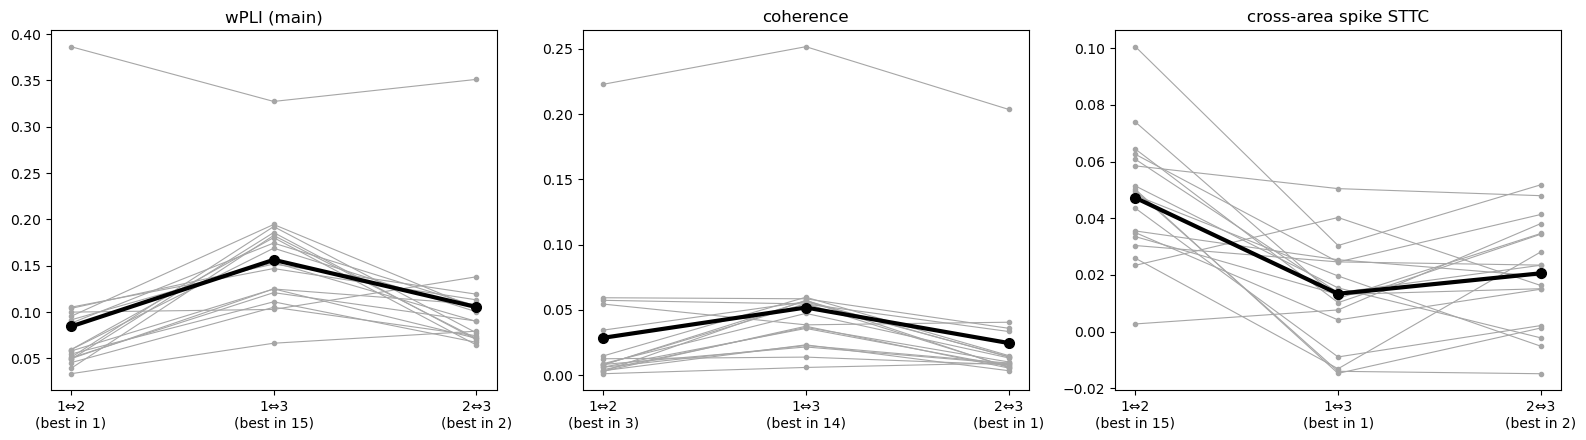

In [3]:
def per_mouse(df, col):
    return df.groupby(["mouse", "area_a", "area_b"])[col].mean().unstack([1, 2])[PAIRS]

und = {"wPLI (main)": per_mouse(lfp, "wpli"), "coherence": per_mouse(lfp, "coh"),
       "cross-area spike STTC": per_mouse(xsttc, "sttc")}
fig, axs = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (lab, pm) in zip(axs, und.items()):
    for m, row in pm.iterrows():
        ax.plot(range(3), row.values, "-o", color="0.65", ms=3, lw=0.8)
    ax.plot(range(3), pm.mean().values, "-o", color="k", lw=3, ms=7)
    best = pm.idxmax(axis=1).value_counts()
    ax.set(xticks=range(3), xticklabels=[f"{name(p)}\n(best in {best.get(p, 0)})" for p in PAIRS], title=lab)
fig.tight_layout()

## 3. Statistics

For each measure: the mean over mice with a bootstrap 95% CI (resampling mice), a Friedman test across the three pairs, and paired Wilcoxon tests between pairs.

In [4]:
def boot_ci(x, n=10_000, seed=0):
    rng = np.random.default_rng(seed)
    b = rng.choice(x, size=(n, len(x))).mean(axis=1)
    return np.quantile(b, [0.025, 0.975])

def summarize(pm, labels):
    rows = {}
    for p, lab in zip(pm.columns, labels):
        lo, hi = boot_ci(pm[p].to_numpy())
        rows[lab] = {"mean": pm[p].mean(), "ci_low": lo, "ci_high": hi, "best in n mice": int((pm.idxmax(axis=1) == p).sum())}
    t = pd.DataFrame(rows).T
    tests = {f"{labels[i]} vs {labels[j]}": sps.wilcoxon(pm.iloc[:, i], pm.iloc[:, j]).pvalue
             for i, j in [(0, 1), (0, 2), (1, 2)]}
    return t, sps.friedmanchisquare(*[pm[c] for c in pm.columns]).pvalue, tests

for lab, pm in und.items():
    t, fr, tests = summarize(pm, [name(p) for p in PAIRS])
    print(f"\n=== {lab}: Friedman p = {fr:.1e}")
    display(t.round(4))
    print({k: f"{v:.1e}" for k, v in tests.items()})


=== wPLI (main): Friedman p = 8.1e-06


,mean,ci_low,ci_high,best in n mice
1⇔2,0.0844,0.0585,0.1255,1.0
1⇔3,0.1564,0.1335,0.1835,15.0
2⇔3,0.1054,0.0840,0.1392,2.0


{'1⇔2 vs 1⇔3': '1.1e-04', '1⇔2 vs 2⇔3': '8.4e-04', '1⇔3 vs 2⇔3': '5.3e-04'}

=== coherence: Friedman p = 7.7e-04


,mean,ci_low,ci_high,best in n mice
1⇔2,0.0285,0.0106,0.0558,3.0
1⇔3,0.0518,0.0341,0.0791,14.0
2⇔3,0.0246,0.0105,0.0481,1.0


{'1⇔2 vs 1⇔3': '3.3e-04', '1⇔2 vs 2⇔3': '7.0e-01', '1⇔3 vs 2⇔3': '3.8e-05'}

=== cross-area spike STTC: Friedman p = 2.3e-04


,mean,ci_low,ci_high,best in n mice
1⇔2,0.0472,0.0375,0.0574,15.0
1⇔3,0.0134,0.0052,0.0215,1.0
2⇔3,0.0206,0.0118,0.0291,2.0


{'1⇔2 vs 1⇔3': '1.1e-04', '1⇔2 vs 2⇔3': '4.2e-04', '1⇔3 vs 2⇔3': '1.7e-01'}


## 3b. wPLI per frequency band

The 1–100 Hz average gives every 0.5-Hz bin equal weight, and two-thirds of those bins lie above 30 Hz, where coupling is weaker.
So wPLI is also averaged within canonical bands, with the mains and equipment lines excluded. These are the per-mouse wPLI spectra from section 1, averaged over the bins of each band.
Note that wPLI is non-negative at every frequency, so leads in one band and lags in another can't cancel. Separate bands only change the weighting.

In [5]:
LINES = [(49.0, 51.0), (52.0, 53.5), (59.0, 61.0), (66.0, 69.0)]
not_line = np.ones_like(f, dtype=bool)
for lo, hi in LINES:
    not_line &= ~((f >= lo) & (f <= hi))
WPLI_BANDS = {"theta 4–8 Hz": (4, 8), "alpha 8–12 Hz": (8, 12), "beta 13–30 Hz": (13, 30),
              "gamma 30–80 Hz": (30, 80), "1–100 Hz": (1, 100)}
wpli_band = {}
rows = []
for bname, (lo, hi) in WPLI_BANDS.items():
    sel = (f >= lo) & (f <= hi) & not_line
    pm = pd.DataFrame({p: [spec[f"m{m}_{p[0]}{p[1]}_wpli"][sel].mean() for m in mice_ids] for p in PAIRS}, index=mice_ids)
    wpli_band[bname] = pm
    t, fr, tests = summarize(pm, [name(p) for p in PAIRS])
    rows.append({"band": bname, **{name(p): pm[p].mean() for p in PAIRS},
                 "1⇔3 strongest in n mice": int(t.loc["1⇔3", "best in n mice"]), "Friedman p": fr,
                 "max Wilcoxon p, 1⇔3 vs others": max(tests["1⇔2 vs 1⇔3"], tests["1⇔3 vs 2⇔3"])})
band_table = pd.DataFrame(rows).set_index("band")
print(f"fraction of 1–100 Hz bins above 30 Hz: {((f > 30) & (f <= 100) & not_line).sum() / ((f >= 1) & (f <= 100) & not_line).sum():.2f}")
band_table.style.format({**{name(p): "{:.3f}" for p in PAIRS}, "Friedman p": "{:.1e}", "max Wilcoxon p, 1⇔3 vs others": "{:.1e}"})

fraction of 1–100 Hz bins above 30 Hz: 0.67


,1⇔2,1⇔3,2⇔3,1⇔3 strongest in n mice,Friedman p,"max Wilcoxon p, 1⇔3 vs others"
band,,,,,,
theta 4–8 Hz,0.128,0.267,0.173,16,1.5e-06,4.2e-04
alpha 8–12 Hz,0.101,0.234,0.149,16,3.2e-06,1.4e-04
beta 13–30 Hz,0.081,0.150,0.108,13,2.8e-05,1.4e-02
gamma 30–80 Hz,0.075,0.148,0.099,15,3.2e-06,1.6e-03
1–100 Hz,0.078,0.153,0.102,15,8.1e-06,4.2e-04


# Q6: directed connectivity

## 4. Who leads whom

For each pair x⇔y, **PSI(x, y) > 0** means x leads y. Granger is shown for both directions.
The plot shows the **net** direction per mouse. Points above zero mean the first area of the pair leads.

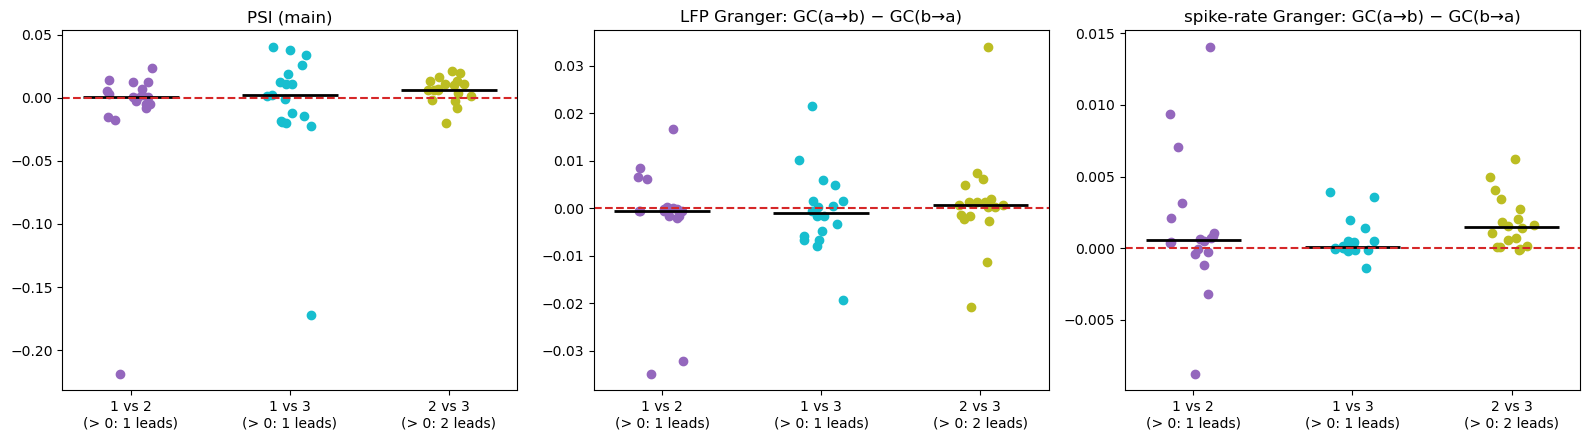

In [6]:
psi_pm = per_mouse(lfp, "psi_ab")
gc_ab, gc_ba = per_mouse(lfp, "gc_ab"), per_mouse(lfp, "gc_ba")
gc_net = gc_ab - gc_ba
spk_gc = spk.pivot_table(index="mouse", columns=["source", "target"], values="gc")
spk_net = pd.DataFrame({p: spk_gc[(p[0], p[1])] - spk_gc[(p[1], p[0])] for p in PAIRS})

fig, axs = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (lab, pm) in zip(axs, [("PSI (main)", psi_pm), ("LFP Granger: GC(a→b) − GC(b→a)", gc_net),
                               ("spike-rate Granger: GC(a→b) − GC(b→a)", spk_net)]):
    for k, p in enumerate(PAIRS):
        v = pm[p].to_numpy()
        ax.scatter(np.full(len(v), k) + np.random.default_rng(k).uniform(-0.15, 0.15, len(v)), v, color=PAIR_COLORS[p])
        ax.hlines(np.median(v), k - 0.3, k + 0.3, color="k", lw=2)
    ax.axhline(0, color="tab:red", ls="--")
    ax.set(xticks=range(3), xticklabels=[f"{a} vs {b}\n(> 0: {a} leads)" for a, b in PAIRS], title=lab)
fig.tight_layout()

## 5. The three directions offered: 1⇒2, 3⇒2, 3⇒1

Directed strength from a to b:
- **PSI:** max(0, PSI(a, b)), meaning only the part pointing in that direction.
- **Granger:** GC(a→b) itself.

In [7]:
DIRS = [(1, 2), (3, 2), (3, 1)]
dname = lambda d: f"{d[0]}⇒{d[1]}"

def directed(pm_signed, d):
    # signed per-mouse PSI is stored for (low, high) pairs: flip the sign if the direction is high → low
    a, b = d
    return pm_signed[(a, b)] if (a, b) in pm_signed.columns else -pm_signed[(b, a)]

psi_dir = pd.DataFrame({d: directed(psi_pm, d) for d in DIRS})
gc_dir = pd.DataFrame({d: (gc_ab[d] if d in gc_ab.columns else gc_ba[(d[1], d[0])]) for d in DIRS})
spk_dir = pd.DataFrame({d: spk_gc[d] for d in DIRS})

for lab, pm in [("PSI, signed (positive = this direction)", psi_dir), ("PSI, directed strength max(0, PSI)", psi_dir.clip(lower=0)),
                ("LFP Granger", gc_dir), ("spike-rate Granger", spk_dir)]:
    t, fr, tests = summarize(pm, [dname(d) for d in DIRS])
    print(f"\n=== {lab}: Friedman p = {fr:.1e}")
    display(t.round(5))
    print({k: f"{v:.1e}" for k, v in tests.items()})

print("\nsign consistency of PSI over mice (fraction of mice where the offered direction is the leading one):")
print({dname(d): round(float((psi_dir[d] > 0).mean()), 2) for d in DIRS})
for d in DIRS:
    print(dname(d), "sign test p =", f"{sps.binomtest(int((psi_dir[d] > 0).sum()), len(psi_dir)).pvalue:.1e}")


=== PSI, signed (positive = this direction): Friedman p = 1.3e-01


,mean,ci_low,ci_high,best in n mice
1⇒2,-0.01055,-0.03725,0.00527,10.0
3⇒2,-0.00629,-0.01052,-0.00137,2.0
3⇒1,0.00467,-0.01279,0.02831,6.0


{'1⇒2 vs 3⇒2': '7.4e-02', '1⇒2 vs 3⇒1': '4.4e-01', '3⇒2 vs 3⇒1': '6.4e-01'}

=== PSI, directed strength max(0, PSI): Friedman p = 1.1e-01


,mean,ci_low,ci_high,best in n mice
1⇒2,0.00458,0.00180,0.00792,10.0
3⇒2,0.00182,0.00015,0.00451,2.0
3⇒1,0.01551,0.00326,0.03581,6.0


{'1⇒2 vs 3⇒2': '9.1e-02', '1⇒2 vs 3⇒1': '5.9e-01', '3⇒2 vs 3⇒1': '3.8e-02'}

=== LFP Granger: Friedman p = 3.4e-02


,mean,ci_low,ci_high,best in n mice
1⇒2,0.01431,0.00547,0.02480,5.0
3⇒2,0.01150,0.00491,0.01980,2.0
3⇒1,0.01605,0.00901,0.02534,11.0


{'1⇒2 vs 3⇒2': '8.0e-01', '1⇒2 vs 3⇒1': '2.3e-01', '3⇒2 vs 3⇒1': '1.2e-02'}

=== spike-rate Granger: Friedman p = 2.8e-04


,mean,ci_low,ci_high,best in n mice
1⇒2,0.00532,0.00315,0.00776,14.0
3⇒2,0.00084,0.00047,0.00128,1.0
3⇒1,0.00110,0.00056,0.00173,3.0


{'1⇒2 vs 3⇒2': '2.3e-05', '1⇒2 vs 3⇒1': '8.4e-04', '3⇒2 vs 3⇒1': '9.7e-01'}

sign consistency of PSI over mice (fraction of mice where the offered direction is the leading one):
{'1⇒2': 0.56, '3⇒2': 0.22, '3⇒1': 0.44}
1⇒2 sign test p = 8.1e-01
3⇒2 sign test p = 3.1e-02
3⇒1 sign test p = 8.1e-01


## 6. Direction per frequency band

Averaging over 1–100 Hz can cancel bands that point in opposite directions. Here PSI is computed separately in theta, beta and low gamma (below the 50 Hz line).
Positive means the first area of the pair leads. The table gives the mean over mice, the number of mice with a positive value, and a Wilcoxon test against 0.
The same file also has wPLI with the mains/equipment lines removed and wPLI in theta, for Q5.

In [8]:
bands = q.compute_psi_bands()
pmb = bands.groupby(["mouse", "area_a", "area_b"]).mean(numeric_only=True).drop(columns="pair")
rows = []
for col in [c for c in pmb.columns if c.startswith("psi")]:
    t = pmb[col].unstack([1, 2])
    for p in PAIRS:
        v = t[p]
        rows.append({"band": col.replace("psi ", ""), "pair": f"{p[0]} vs {p[1]}", "mean PSI": v.mean(),
                     "mice > 0 (first leads)": int((v > 0).sum()), "wilcoxon p": sps.wilcoxon(v).pvalue})
psi_table = pd.DataFrame(rows).pivot(index="band", columns="pair")
display(psi_table.round(4))

wpli_clean = pmb["wpli_no_lines"].unstack([1, 2])[PAIRS]
wpli_theta = pmb["wpli_theta"].unstack([1, 2])[PAIRS]
for lab, pm in [("wPLI 1–100 Hz without mains/equipment lines", wpli_clean), ("wPLI theta 4–10 Hz", wpli_theta)]:
    t, fr, tests = summarize(pm, [name(p) for p in PAIRS])
    print(f"\n=== {lab}: Friedman p = {fr:.1e}"); display(t.round(4)); print({k: f"{v:.1e}" for k, v in tests.items()})

mean PSI                 mice > 0 (first leads)                \
pair             1 vs 2  1 vs 3  2 vs 3                 1 vs 2 1 vs 3 2 vs 3   
band                                                                           
1-100 Hz        -0.0106 -0.0047  0.0063                     10     10     14   
beta 12-30 Hz   -0.0007 -0.0003  0.0009                      6     10     13   
gamma 30-48 Hz  -0.0008 -0.0016  0.0012                      3      6     16   
theta 4-10 Hz   -0.0053  0.0109  0.0040                      8     12     12   

               wilcoxon p                  
pair               1 vs 2  1 vs 3  2 vs 3  
band                                       
1-100 Hz           0.8986  0.7660  0.0139  
beta 12-30 Hz      0.0304  0.7019  0.1540  
gamma 30-48 Hz     0.0432  0.1297  0.0019  
theta 4-10 Hz      0.7337  0.0432  0.1084


=== wPLI 1–100 Hz without mains/equipment lines: Friedman p = 8.1e-06


,mean,ci_low,ci_high,best in n mice
1⇔2,0.0779,0.0543,0.1164,1.0
1⇔3,0.1529,0.1303,0.1790,15.0
2⇔3,0.1016,0.0818,0.1331,2.0


{'1⇔2 vs 1⇔3': '1.4e-04', '1⇔2 vs 2⇔3': '8.4e-04', '1⇔3 vs 2⇔3': '4.2e-04'}

=== wPLI theta 4–10 Hz: Friedman p = 1.5e-06


,mean,ci_low,ci_high,best in n mice
1⇔2,0.1218,0.0786,0.1806,0.0
1⇔3,0.2631,0.2072,0.3260,16.0
2⇔3,0.1690,0.1330,0.2154,2.0


{'1⇔2 vs 1⇔3': '7.6e-06', '1⇔2 vs 2⇔3': '3.4e-03', '1⇔3 vs 2⇔3': '4.2e-04'}


## 7. Forward vs reverse Granger for the offered directions

For a direction to be "the" directed connection, it should be stronger than its reverse.

In [9]:
lgc = lfp.groupby(["mouse", "area_a", "area_b"])[["gc_ab", "gc_ba"]].mean()
rows = []
for a, b in DIRS:
    lo, hi = min(a, b), max(a, b)
    t = lgc.xs((lo, hi), level=[1, 2])
    fwd_l, rev_l = (t.gc_ab, t.gc_ba) if a < b else (t.gc_ba, t.gc_ab)
    fwd_s, rev_s = spk_gc[(a, b)], spk_gc[(b, a)]
    rows.append({"direction": dname((a, b)),
                 "LFP GC forward": fwd_l.mean(), "LFP GC reverse": rev_l.mean(), "LFP fwd > rev (mice)": int((fwd_l > rev_l).sum()),
                 "LFP p": sps.wilcoxon(fwd_l, rev_l).pvalue,
                 "spike GC forward": fwd_s.mean(), "spike GC reverse": rev_s.mean(), "spike fwd > rev (mice)": int((fwd_s > rev_s).sum()),
                 "spike p": sps.wilcoxon(fwd_s, rev_s).pvalue})
pd.DataFrame(rows).set_index("direction").round(4)

,LFP GC forward,LFP GC reverse,LFP fwd > rev (mice),LFP p,spike GC forward,spike GC reverse,spike fwd > rev (mice),spike p
direction,,,,,,,,
1⇒2,0.0143,0.0164,6,0.3465,0.0053,0.0038,12,0.1084
3⇒2,0.0115,0.0126,6,0.6095,0.0008,0.0026,2,0.0001
3⇒1,0.0160,0.0154,10,0.4683,0.0011,0.0017,7,0.0665


## 8. Answers

**Q5: areas 1⇔3.**
- Both LFP measures agree: wPLI is strongest for 1⇔3 in 15 of 18 mice, and coherence in 14 of 18.
- The coupling peaks in theta (~7 Hz), so the reported value is theta-band wPLI (4–8 Hz).
- 1⇔3 is also the strongest pair in alpha, beta and gamma separately, and over 1–100 Hz (section 3b).
- **Caveat:** spike co-firing (cross-area STTC) is strongest for **1⇔2** in 15 of 18 mice. The answer depends on the signal. LFP synchrony is the usual measure of connectivity between areas, and it is what's reported here.

**Q6: not enough data / no differences.**
- None of the offered directions is stronger than its reverse on any measure (section 7).
- PSI shows no consistent direction for 1⇒2 or 3⇒1.
- 3⇒2 is consistently **reversed**: area 2 leads area 3 (PSI 1–100 Hz in 14 of 18 mice; spike Granger 2⇒3 > 3⇒2 in 16 of 18).
- Raw Granger magnitudes rank the offered directions differently for LFP (3⇒1) and spikes (1⇒2).

In [10]:
from c2p.questionnaire import fill_pdf, record_answer, record_meta

# Q5 table: theta-band wPLI (4-8 Hz, where the coupling peaks), mean over mice, bootstrap CI
t5, fr5, tests5 = summarize(wpli_band["theta 4–8 Hz"], [name(p) for p in PAIRS])
assert 3 * max(tests5["1⇔2 vs 1⇔3"], tests5["1⇔3 vs 2⇔3"]) < 0.05
assert (3 * band_table["max Wilcoxon p, 1⇔3 vs others"] < 0.05).all()          # same winner in every band
rows5 = [(f"{r['mean']:.3f}", f"[{r.ci_low:.3f}, {r.ci_high:.3f}]", "wPLI (unitless)") for _, r in t5.iterrows()]
bt = band_table
st = und["cross-area spike STTC"]
expl5 = (
    f"I measured LFP connectivity between every pair of areas over the whole recording. Because all channels share an "
    f"external reference and large transients (movement/EMG) appear in all areas at the same instant, I used local "
    f"bipolar derivations (6 per area, spread over depth) and the weighted phase lag index (wPLI), which ignores "
    f"zero-lag coupling. wPLI was computed from 2-s segments at each frequency between all 36 channel pairs of each "
    f"area pair and averaged over channel pairs, giving one wPLI spectrum per mouse and pair. Coupling peaked in the "
    f"theta band, so the table reports theta wPLI (4–8 Hz) with bootstrap CIs over mice: areas 1 and 3 were the most "
    f"strongly connected ({t5.loc['1⇔3', 'mean']:.3f} vs {t5.loc['1⇔2', 'mean']:.3f} for 1⇔2 and "
    f"{t5.loc['2⇔3', 'mean']:.3f} for 2⇔3), in {int(t5.loc['1⇔3', 'best in n mice'])} of 18 mice (Friedman "
    f"p < 0.001; Wilcoxon p <= {min(1, 3 * max(tests5['1⇔2 vs 1⇔3'], tests5['1⇔3 vs 2⇔3'])):.3f} against each other pair). The ranking was the same when wPLI was averaged "
    f"separately in the alpha, beta and gamma bands and over 1–100 Hz (mains and equipment lines excluded; 1⇔3 "
    f"strongest in {bt['1⇔3 strongest in n mice'].min()}–{bt['1⇔3 strongest in n mice'].max()} of 18 mice), and "
    f"coherence agreed. Spike co-firing between units of different areas (STTC, 100 ms) was instead strongest for 1⇔2 "
    f"({int((st.idxmax(axis=1) == (1, 2)).sum())} of 18 mice), so the answer depends on the signal; I report "
    f"LFP-based connectivity, the usual measure between areas."
)
expl5 += " Pairwise p-values are Bonferroni-corrected for the three comparisons."
record_answer(5, choice=1, rows=rows5, explanation=expl5)          # options in reading order: 1⇔2, 1⇔3, 2⇔3, not enough data

# Q6 table: signed PSI (1-100 Hz) for the offered directions, positive = stated direction
t6, fr6, _ = summarize(psi_dir, [dname(d) for d in DIRS])
rows6 = [(f"{r['mean']:+.4f}", f"[{r.ci_low:+.4f}, {r.ci_high:+.4f}]", "PSI (unitless)") for _, r in t6.iterrows()]
pos = {d: int((psi_dir[d] > 0).sum()) for d in DIRS}
expl6 = (
    f"I estimated the direction of coupling on the same bipolar LFP signals with the phase slope index (PSI, "
    f"insensitive to zero-lag mixing) over 1–100 Hz and separately in theta, beta and gamma, and with Granger causality "
    f"on the LFP (250 Hz, 100 ms of history) and on population spike rates (10-ms bins). Values are per mouse, averaged "
    f"over channel pairs; the table gives the mean signed PSI over mice with a bootstrap CI, positive meaning the stated "
    f"direction. None of the three offered directions was consistently supported: PSI for 1⇒2 and 3⇒1 was close to zero "
    f"with signs split across mice ({pos[(1, 2)]} and {pos[(3, 1)]} of 18 positive), and 3⇒2 was consistently reversed "
    f"(area 2 leads area 3: PSI in {18 - pos[(3, 2)]} of 18 mice, spike-rate Granger 2⇒3 > 3⇒2 in "
    f"{int((spk_gc[(2, 3)] > spk_gc[(3, 2)]).sum())} of 18). No offered direction was stronger than its reverse in either "
    f"Granger analysis, and the raw Granger magnitudes ranked the directions differently for LFP (3⇒1) and spikes "
    f"(1⇒2). Because the directed measures disagree and none supports one of the offered directions, I answer not "
    f"enough data / no differences."
)
record_answer(6, choice=3, rows=rows6, explanation=expl6)          # options in reading order: 1⇒2, 3⇒2, 3⇒1, not enough data
record_meta(5, confidence=4, consensus=3)
record_meta(6, confidence=3, consensus=2)
print(len(expl5.split()), "and", len(expl6.split()), "words")
print(fill_pdf())

218 and 180 words


/home/dariosannino/con2phys/docs/questionnaire_filled.pdf
